In [1]:
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import seaborn as sns

/Users/aigulnasibullina/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
%matplotlib qt5

/var/folders/p0/0zzg8mps09x6x0gp674ghtg80000gn/T/ipykernel_34135/3848746355.py:20: RuntimeWarning: Fiducial point nasion not found, assuming identity unknown to head transformation
  selected_montage.plot(show_names=True)


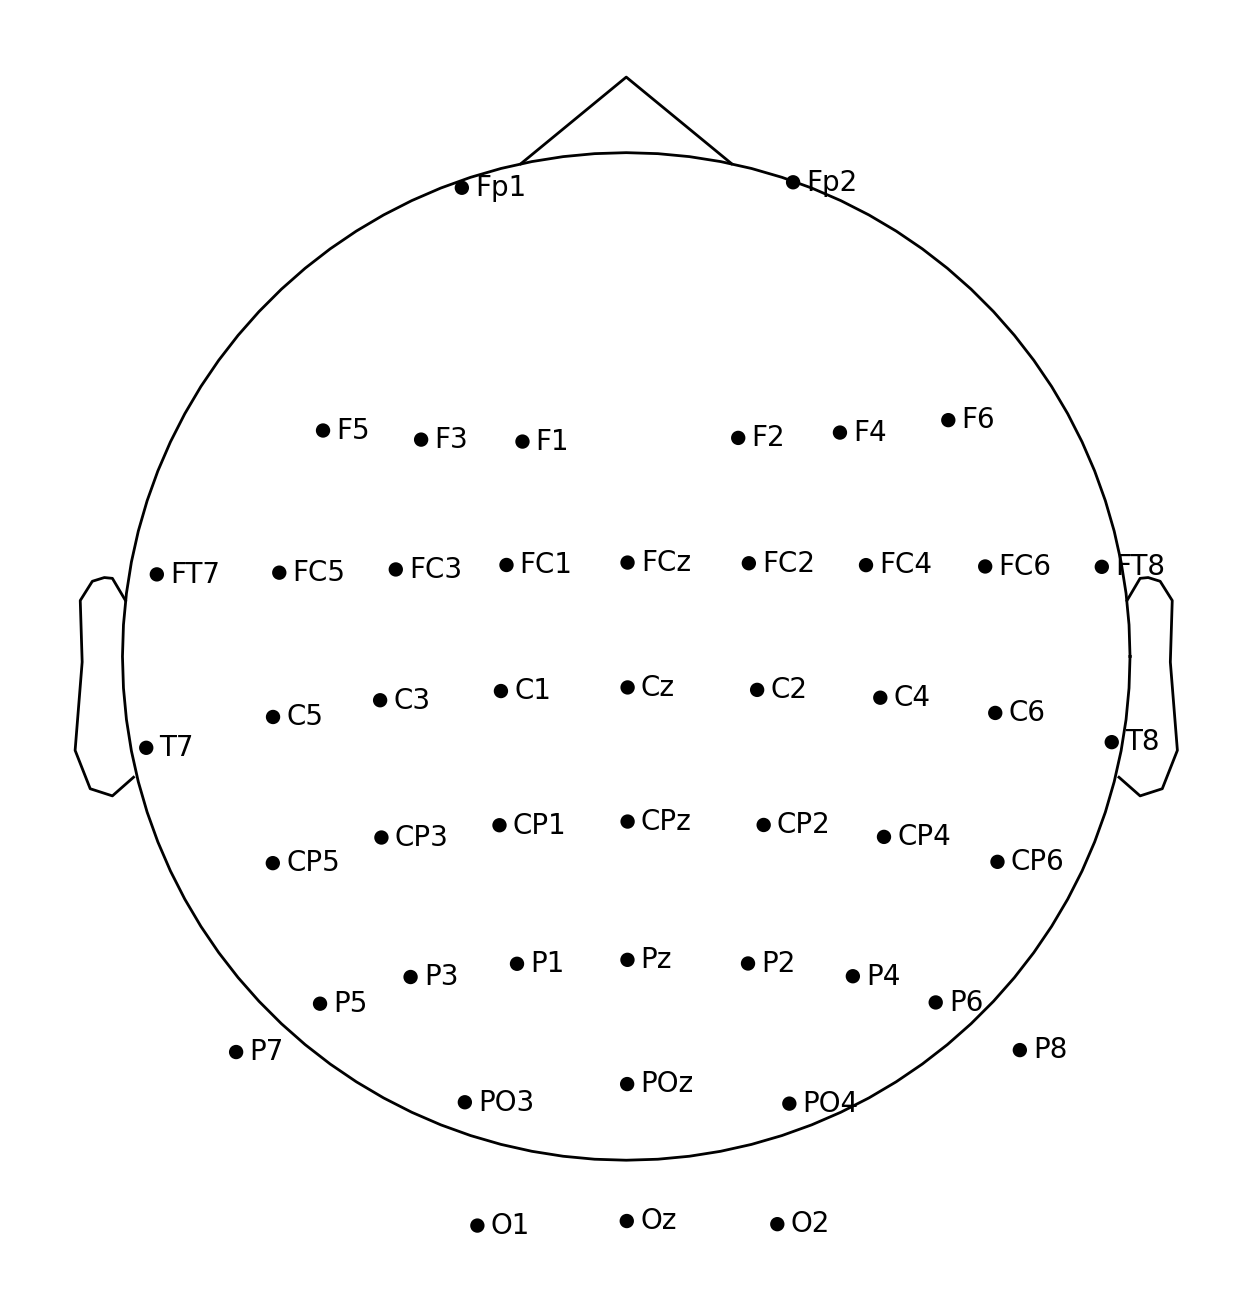

2025-03-28 13:19:39.334 python[34135:1731770] +[IMKClient subclass]: chose IMKClient_Modern
2025-03-28 13:19:39.334 python[34135:1731770] +[IMKInputSession subclass]: chose IMKInputSession_Modern


In [3]:
# Загрузка стандартного монтажа 10-20
montage = mne.channels.make_standard_montage('standard_1020')

electrodes_to_use = ['Fp1', 'Fp2', 'F3', 'F1', 'F2', 'F4', 'FC5', 'FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'FC6', 
                     'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6', 'CP5', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'CP6', 
                     'P5', 'P3', 'P1', 'Pz', 'P2', 'P4', 'P6', 'PO3', 'POz', 'PO4', 'O1', 'Oz', 'O2', 
                     'F5', 'FT7', 'T7', 'P7', 'F6', 'FT8', 'T8', 'P8']


# Получаем все позиции каналов, доступные в монтаже
ch_pos = montage.get_positions()['ch_pos']

# Фильтруем каналы по списку интересующих электродов
selected_ch_pos = {ch: pos for ch, pos in ch_pos.items() if ch in electrodes_to_use}

# Создаем новый DigMontage только с нужными электродами
selected_montage = mne.channels.make_dig_montage(ch_pos=selected_ch_pos)

# Визуализация монтажа
selected_montage.plot(show_names=True)


In [4]:
selected_montage

<DigMontage | 0 extras (headshape), 0 HPIs, 0 fiducials, 48 channels>

2025-03-13 15:43:23.049 python[13928:362219] +[IMKClient subclass]: chose IMKClient_Modern
2025-03-13 15:43:23.049 python[13928:362219] +[IMKInputSession subclass]: chose IMKInputSession_Modern


# Importing data from EEG devices

MNE includes various functions and utilities for reading EEG data and electrode
locations.


## BrainVision (.vhdr, .vmrk, .eeg)

The BrainVision file format consists of three separate files:

1. A text header file (``.vhdr``) containing meta data.
2. A text marker file (``.vmrk``) containing information about events in the
   data.
3. A binary data file (``.eeg``) containing the voltage values of the EEG.

Both text files are based on the [INI format](https://en.wikipedia.org/wiki/INI_file)
consisting of

* sections marked as ``[square brackets]``,
* comments marked as ``; comment``,
* and key-value pairs marked as ``key=value``.

Brain Products provides documentation for their core BrainVision file format.
The format specification is hosted on the
[Brain Products website](https://www.brainproducts.com/support-resources/brainvision-core-data-format-1-0/).

BrainVision EEG files can be read using :func:`mne.io.read_raw_brainvision`,
passing the ``.vhdr`` header file as the argument.

<div class="alert alert-danger"><h4>Warning</h4><p>Renaming BrainVision files can be problematic due to their
             multi-file structure. See this
             [example](https://mne.tools/mne-bids/stable/auto_examples/rename_brainvision_files.html#sphx-glr-auto-examples-rename-brainvision-files-py)
             for instructions.</p></div>

<div class="alert alert-info"><h4>Note</h4><p>For *writing* BrainVision files, take a look at the :mod:`mne.export`
          module, which used the [pybv](https://pypi.org/project/pybv/) Python
          package.</p></div>

In [4]:
# raw = mne.io.read_raw_brainvision('/Volumes/T7 Shield/TI_Vivedness_Conds/Course2/DG/NeoRec_2025-02-26_11-47-08.vhdr', preload=True)

Extracting parameters from /Volumes/T7 Shield/TI_Vivedness_Conds/Course2/DG/NeoRec_2025-02-26_11-47-08.vhdr...
Setting channel info structure...
Reading 0 ... 727766  =      0.000 ...   363.883 secs...


In [5]:
raw = mne.io.read_raw_brainvision('/Users/aigulnasibullina/Downloads/Kolya_TEMP_NEW/COLD_TI/NeoRec_2025-03-20_18-41-18.vhdr', preload=True)

Extracting parameters from /Users/aigulnasibullina/Downloads/Kolya_TEMP_NEW/COLD_TI/NeoRec_2025-03-20_18-41-18.vhdr...
Setting channel info structure...
Reading 0 ... 109989  =      0.000 ...   219.978 secs...


In [99]:
raw = mne.io.read_raw_brainvision('/Users/aigulnasibullina/Downloads/Kolya_TEMP_NEW/COLD_TS/NeoRec_2025-03-20_18-31-30.vhdr', preload=True)

Extracting parameters from /Users/aigulnasibullina/Downloads/Kolya_TEMP_NEW/COLD_TS/NeoRec_2025-03-20_18-31-30.vhdr...
Setting channel info structure...
Reading 0 ... 107921  =      0.000 ...   215.842 secs...


In [53]:
raw = mne.io.read_raw_brainvision('/Users/aigulnasibullina/Downloads/MA/HOT_TS_RH/NeoRec_2025-03-15_13-55-37.vhdr', preload=True)

Extracting parameters from /Users/aigulnasibullina/Downloads/MA/HOT_TS_RH/NeoRec_2025-03-15_13-55-37.vhdr...
Setting channel info structure...
Reading 0 ... 108235  =      0.000 ...   216.470 secs...


In [65]:
raw = mne.io.read_raw_brainvision('/Users/aigulnasibullina/Downloads/MA/HOT_TI_RH/NeoRec_2025-03-15_14-03-26.vhdr', preload=True)

Extracting parameters from /Users/aigulnasibullina/Downloads/MA/HOT_TI_RH/NeoRec_2025-03-15_14-03-26.vhdr...
Setting channel info structure...
Reading 0 ... 119885  =      0.000 ...   239.770 secs...


In [76]:
raw = mne.io.read_raw_brainvision('/Users/aigulnasibullina/Downloads/MA/COLD_TI_RH/NeoRec_2025-03-15_14-19-50.vhdr', preload=True)

Extracting parameters from /Users/aigulnasibullina/Downloads/MA/COLD_TI_RH/NeoRec_2025-03-15_14-19-50.vhdr...
Setting channel info structure...
Reading 0 ... 119174  =      0.000 ...   238.348 secs...


In [87]:
raw = mne.io.read_raw_brainvision('//Users/aigulnasibullina/Downloads/MA/COLD_TS_RH/NeoRec_2025-03-15_14-11-54.vhdr', preload=True)

Extracting parameters from //Users/aigulnasibullina/Downloads/MA/COLD_TS_RH/NeoRec_2025-03-15_14-11-54.vhdr...
Setting channel info structure...
Reading 0 ... 107658  =      0.000 ...   215.316 secs...


In [111]:
raw = mne.io.read_raw_brainvision('/Users/aigulnasibullina/Downloads/Kolya_TEMP_NEW/COLD_TI/NeoRec_2025-03-20_18-41-18.vhdr', preload=True)

Extracting parameters from /Users/aigulnasibullina/Downloads/Kolya_TEMP_NEW/COLD_TI/NeoRec_2025-03-20_18-41-18.vhdr...
Setting channel info structure...
Reading 0 ... 109989  =      0.000 ...   219.978 secs...


In [8]:
# def patched_str_to_meas_date(date_str):
#     return None  # Принудительно убираем дату

# mne.io.brainvision.brainvision._str_to_meas_date = patched_str_to_meas_date

# raw = mne.io.read_raw_brainvision('/Users/aigulnasibullina/Downloads/HOT_TS_LH_1/NeoRec_2025-03-05_13-20-59.vhdr', preload=True)

Extracting parameters from /Users/aigulnasibullina/Downloads/HOT_TS_LH_1/NeoRec_2025-03-05_13-20-59.vhdr...
Setting channel info structure...
Reading 0 ... 177609  =      0.000 ...   355.218 secs...


In [112]:
raw.set_montage(selected_montage);

/var/folders/p0/0zzg8mps09x6x0gp674ghtg80000gn/T/ipykernel_34135/2299241346.py:1: RuntimeWarning: Fiducial point nasion not found, assuming identity unknown to head transformation
  raw.set_montage(selected_montage);


In [113]:
raw.filter(1, 30, fir_design='firwin', skip_by_annotation='edge')

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 30 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 30.00 Hz
- Upper transition bandwidth: 7.50 Hz (-6 dB cutoff frequency: 33.75 Hz)
- Filter length: 1651 samples (3.302 s)



[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   4 out of   4 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done  48 out of  48 | elapsed:    0.1s finished


<RawBrainVision | NeoRec_2025-03-20_18-41-18.eeg, 49 x 109990 (220.0 s), ~41.2 MiB, data loaded>

In [114]:
events, ids = mne.events_from_annotations(raw, event_id={'12/stim': 12, '13/rest': 13})

Used Annotations descriptions: ['12/stim', '13/rest']


In [115]:
epochs = mne.Epochs(raw, events, event_id=ids, tmin=0.0, tmax=4.0, baseline=(0, 0), preload=True)      

Not setting metadata
30 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 30 events and 2001 original time points ...
0 bad epochs dropped


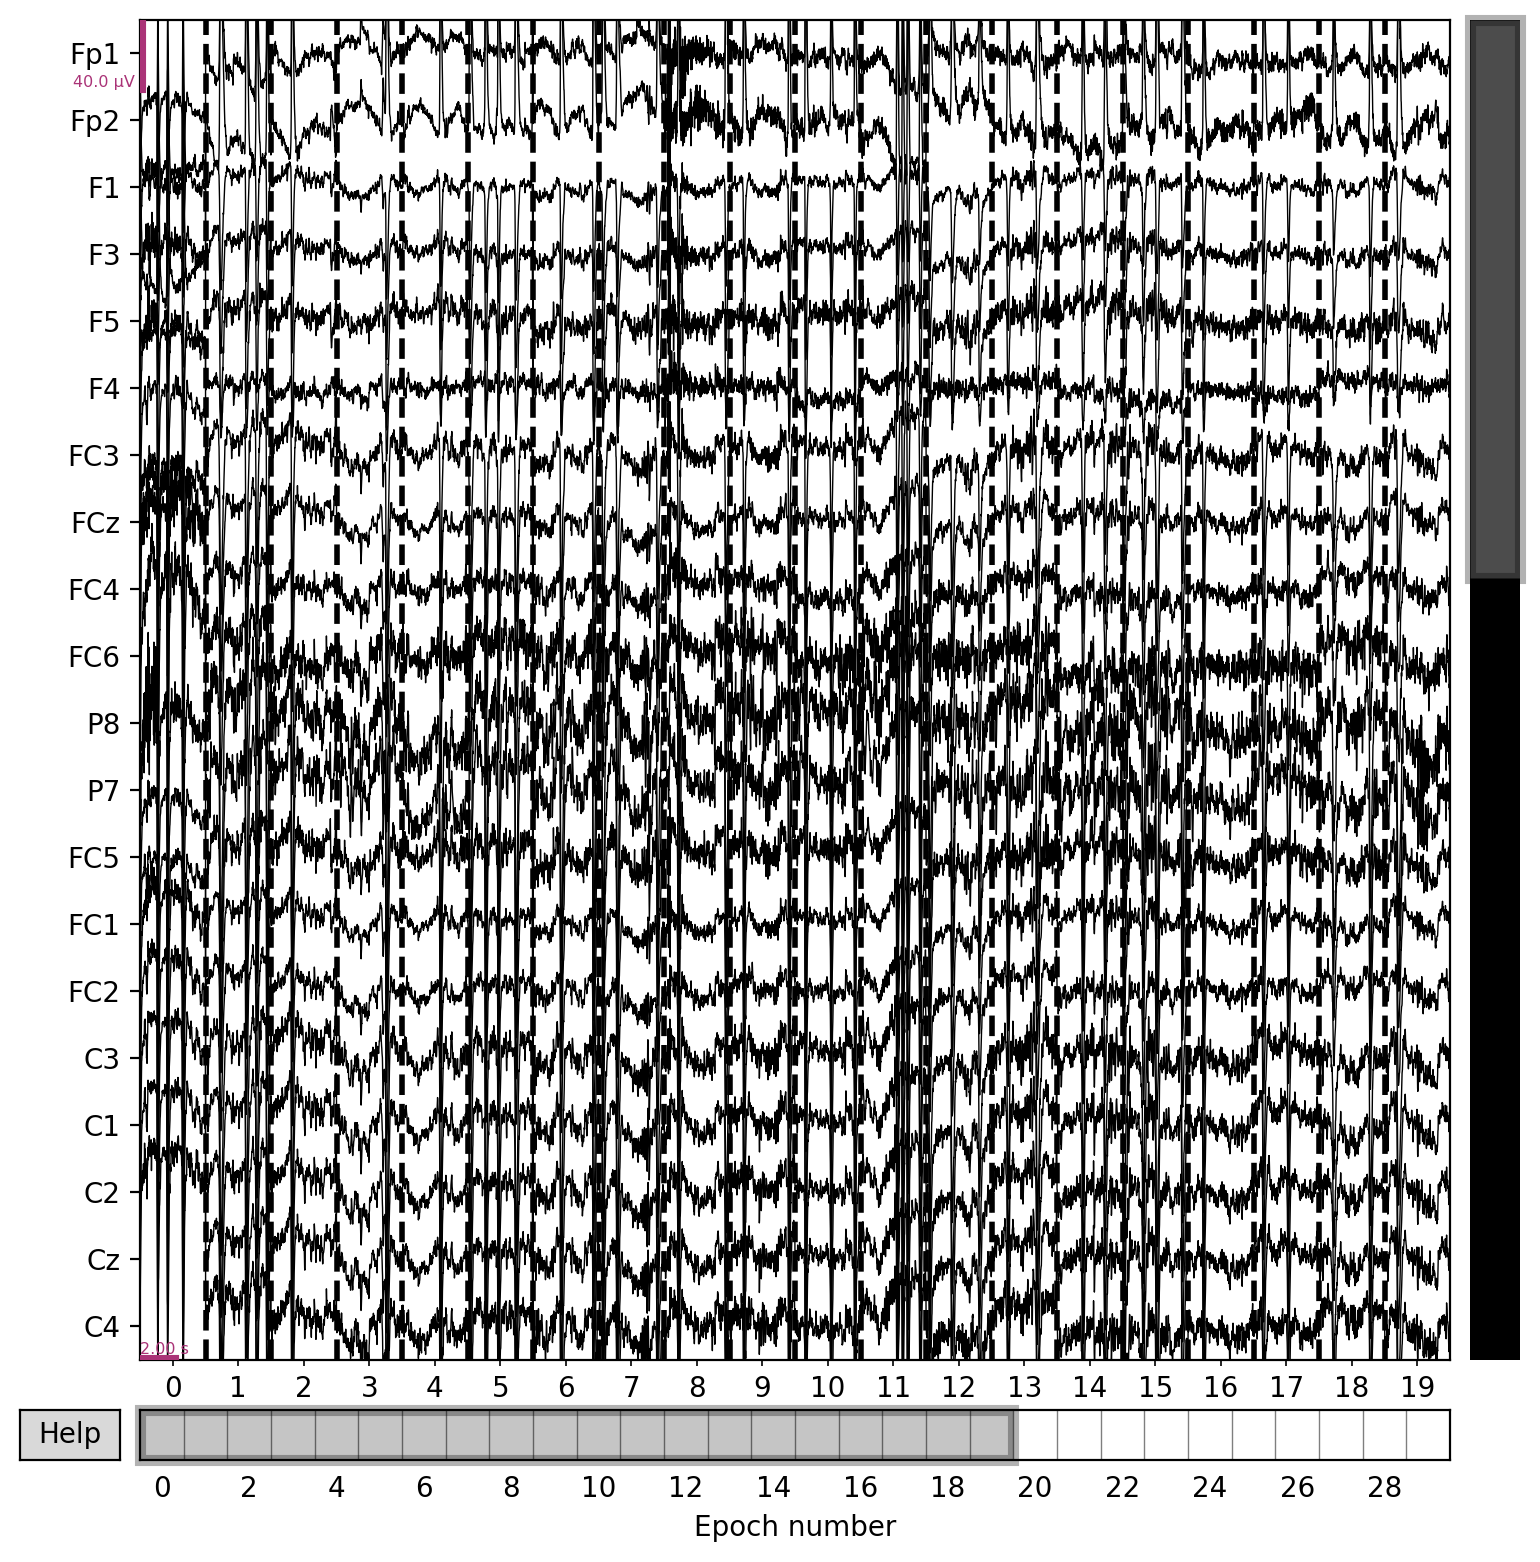

Dropped 0 epochs: 
The following epochs were marked as bad and are dropped:
[]
Channels marked as bad:
none


In [32]:
epochs.plot()

In [16]:
epochs.interpolate_bads()

Setting channel interpolation method to {'eeg': 'spline'}.


/var/folders/p0/0zzg8mps09x6x0gp674ghtg80000gn/T/ipykernel_34135/3709101561.py:1: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs.interpolate_bads()


<Epochs | 30 events (all good), 0 – 4 s (baseline 0 – 0 s), ~22.5 MiB, data loaded,
 '12/stim': 15
 '13/rest': 15>

    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


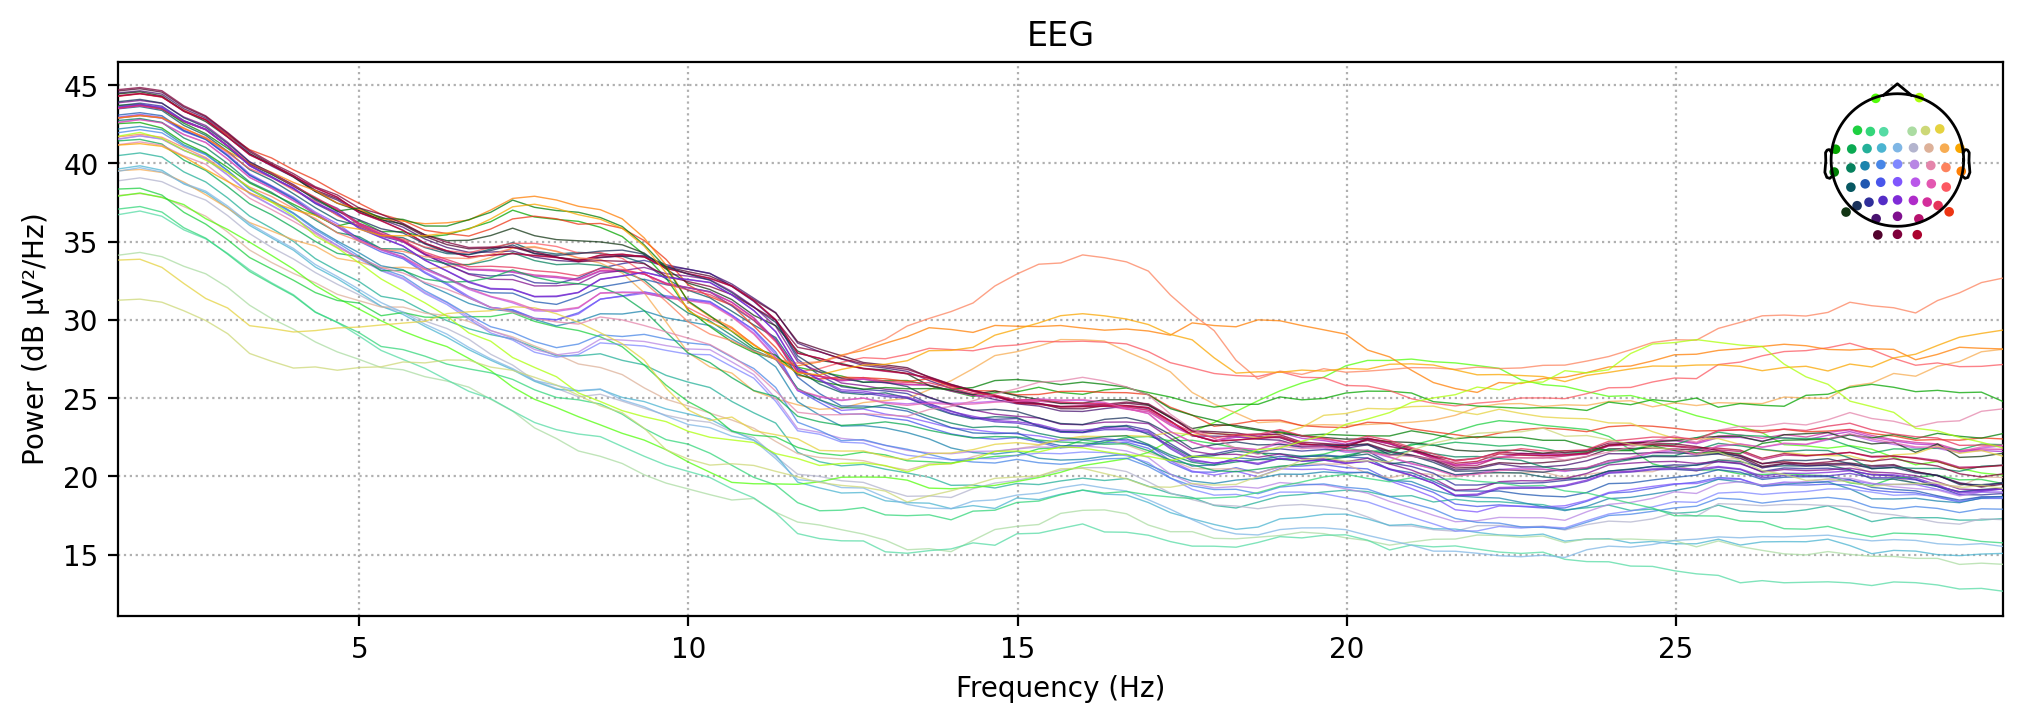

In [116]:
psd_ts = epochs['stim'].compute_psd(method="multitaper",tmin=1, tmax=4, fmin=1, fmax=30)
psd_ts.plot()

In [117]:
psd_rest = epochs['rest'].compute_psd(method="multitaper",tmin=1, tmax=4, fmin=1, fmax=30)
psd_rest.plot()
psd_rest

    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


Data type,Power Spectrum
Units,eeg: V²/Hz
Data source,Epochs
Number of epochs,15
Dims,"epoch, channel, freq"
Estimation method,multitaper
Number of channels,48
Number of frequency bins,87
Frequency range,1.33 – 29.98 Hz


In [118]:
# Получение данных PSD и частот
psds_rest_full = psd_rest.get_data()  # Получение PSD данных для rst
psds_ts_full = psd_ts.get_data()  # Получение PSD данных для SMR
ffreqs = psd_rest.freqs  # Частоты одинаковы для всехb

In [48]:
psds_rest_full

array([[[2.79453697e-10, 3.07170522e-10, 2.73879746e-10, ...,
         1.51456512e-10, 1.32792138e-10, 1.10612088e-10],
        [4.98847222e-10, 5.71727025e-10, 5.93457771e-10, ...,
         2.96636115e-10, 2.03543666e-10, 2.01262842e-10],
        [1.87861507e-10, 2.13955033e-10, 2.62445760e-10, ...,
         1.09160545e-10, 7.98053066e-11, 7.05632214e-11],
        ...,
        [1.03055818e-09, 1.03699340e-09, 1.38510556e-09, ...,
         5.83639894e-10, 4.21732301e-10, 3.93975295e-10],
        [1.06628181e-09, 1.08956194e-09, 2.08889758e-09, ...,
         1.13471042e-09, 4.58100570e-10, 4.27584926e-10],
        [1.06659170e-10, 1.12858058e-10, 1.49895727e-10, ...,
         7.88629249e-11, 9.22770161e-11, 7.25385600e-11]],

       [[2.26016579e-10, 2.20899473e-10, 2.09514629e-10, ...,
         7.70161228e-11, 7.33076434e-11, 6.05676582e-11],
        [3.52379642e-10, 3.20487163e-10, 2.63250647e-10, ...,
         8.79818355e-11, 7.47439220e-11, 7.58711595e-11],
        [1.36734749e-10, 

In [21]:
psds_rest_full.shape


(15, 48, 87)

In [22]:
ffreqs.shape

(87,)

In [119]:
psd_rest_full = 10. * np.log10(psd_rest)
psd_ts_full = 10. * np.log10(psd_ts)

In [120]:
####FULL SPECTRUM
# sns.lineplot(x=ffreqs, y=psd_rest_full.mean(0)[11],color='black', label="rest", linewidth=1.5)
# sns.lineplot(x=ffreqs, y=psd_ts_full.mean(0)[11], color='red', label="ts", linewidth=1.5)

# Построение графиков для полного спектра
plt.figure(figsize=(10, 6))

channel_name = 'C3'  # Введите название нужного канала
channel_idx = raw.ch_names.index(channel_name)

# Линейные графики для состояния покоя и тактильной стимуляции
sns.lineplot(x=ffreqs, y=psd_rest_full.mean(0)[channel_idx], color='black', label="Rest", linewidth=1.5)
sns.lineplot(x=ffreqs, y=psd_ts_full.mean(0)[channel_idx], color='red', label="Tactile Stimulation (TS)", linewidth=1.5)
# label="Tactile Stimulation (TS)"
# Подписи осей
plt.xlabel('Frequency (Hz)', fontsize=12)
plt.ylabel('Power Spectral Density (µV²/Hz)', fontsize=12)

# Заголовок графика
plt.title(f'Power Spectral Density (PSD) for Rest and Tactile Stimulation Cold - {channel_name}', fontsize=14)

# Настройка легенды
plt.legend(loc='upper right', fontsize=12)

# Отображение графика
plt.show()


/Users/aigulnasibullina/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Users/aigulnasibullina/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Users/aigulnasibullina/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Users/aigulnasibullina/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and

In [121]:
# Вычисление PSD для состояния 'rest' с помощью метода "welch"
psd_rest = epochs['rest'].compute_psd(method="multitaper", fmin=11, fmax=14)
psd_ts = epochs['stim'].compute_psd(method="multitaper", fmin=11, fmax=14)

# Получение данных PSD (вернет массив)
psd_rest_data = psd_rest.get_data()  # форма (n_epochs, n_channels, n_freqs)
psd_ts_data = psd_ts.get_data()

# Вычисление среднего по частотам и по эпохам
rest_mean = psd_rest_data.mean(axis=0).mean(axis=1)  # среднее по эпохам и частотам
ts_mean = psd_ts_data.mean(axis=0).mean(axis=1)

# Вычисление ERD
erd = (ts_mean - rest_mean) / rest_mean * 100
# erd = (rest_mean - ts_mean) / rest_mean * 100

# Визуализация ERD на топографической карте
# mne.viz.plot_topomap(erd, raw.info)
# erd = ts_mean
mne.viz.plot_topomap(erd, raw.info)
# np.save()
# сохранить имена

    Using multitaper spectrum estimation with 7 DPSS windows
    Using multitaper spectrum estimation with 7 DPSS windows


(<matplotlib.image.AxesImage at 0x3370d77d0>,
 <matplotlib.contour.QuadContourSet at 0x336fb1f50>)

In [22]:
print(psd_rest.freqs)
print(psd_ts.freqs)


[11.33238897 11.49904175 11.66569453 11.8323473  11.99900008 12.16565286
 12.33230564 12.49895842 12.6656112 ]
[11.33238897 11.49904175 11.66569453 11.8323473  11.99900008 12.16565286
 12.33230564 12.49895842 12.6656112 ]


In [23]:
psd_rest = epochs['rest'].compute_psd(method="welch", fmin=11.2, fmax=12.7)
psd_ts = epochs['stim'].compute_psd(method="welch", fmin=11.2, fmax=12.7)
print(psd_rest.freqs)  # Проверить частоты


Effective window size : 1.024 (s)
Effective window size : 1.024 (s)
[11.71875   12.6953125]


In [30]:
erd

array([ 24.48018654,   2.50236827,  20.64451439,  33.49172032,
        42.84536614,  25.14840539,  25.9836131 ,  41.70137128,
        13.65919715,  18.98618988,  23.71224411, -23.0303067 ,
        -4.61125565,  45.8654591 ,  24.64526711,   1.78238415,
        47.00876432,  25.39527844, -13.84289443,  -0.99404001,
        12.21676902,  15.28641758,  37.65493044,  22.50410467,
       -17.51323178,  33.14757796, -11.22075925,  -7.1642812 ,
        -1.77760526,  24.77566051,  17.93778206,  37.63847868,
        -8.89045056, -26.48015131,   6.12188364, -21.59681897,
       -23.78719215,   6.83337528, -21.51492263, -27.43622799,
       -30.88560793, -22.73156077, -23.07713764, -25.37846131,
       -28.54426775,   8.68201789,  30.4397734 ,  26.29100147])

In [21]:
psd_rest_data.shape

(20, 48, 9)

In [71]:
psd_rest_mean_freq = psd_rest_data.mean(axis=2)

In [72]:
rest_med = np.median(psd_rest_mean_freq, axis=0)

In [73]:
psd_ts_mean_freq = psd_ts_data.mean(axis=2)

In [74]:
ts_med = np.median(psd_ts_mean_freq, axis=0)

In [75]:
erd_med = (rest_med - ts_med) / rest_med * 100

In [76]:
mne.viz.plot_topomap(erd_med, raw.info)

(<matplotlib.image.AxesImage at 0x33bb1ce50>,
 <matplotlib.contour.QuadContourSet at 0x15bb3b650>)

In [77]:
rest_med = psd_rest_data.median(axis=0).median(axis=1)  

AttributeError: 'numpy.ndarray' object has no attribute 'median'

In [42]:
rest_med = np.median(np.median(psd_rest_data, axis=2), axis=0)

In [43]:
ts_med = np.median(np.median(psd_ts_data, axis=2), axis=0)

In [44]:
erd_med = (rest_med - ts_med) / rest_med * 100

In [45]:
mne.viz.plot_topomap(erd_med, raw.info)

(<matplotlib.image.AxesImage at 0x34c989d10>,
 <matplotlib.contour.QuadContourSet at 0x15888c490>)

In [36]:
erd_med.shape

(48,)

In [ ]:
rest_med = np.median(psd_rest_data, axis = [0,1])rest_mean = psd_rest_data.mean(axis=0).mean(axis=1)  # среднее по эпохам и частотам
ts_mean = psd_ts_data.mean(axis=0).mean(axis=1)

# Вычисление ERD
erd = (rest_mean - ts_mean) / rest_mean * 100

# Визуализация ERD на топографической карте
# mne.viz.plot_topomap(erd, raw.info)
# erd = ts_mean
mne.viz.plot_topomap(erd, raw.info)